

# Phase 4: Context Window Comparison

**Web Mining and Applied NLP — Project 03**  
**Author:** Beth Spornitz

## Purpose

This notebook compares word co-occurrence results using context windows of 2 and 3 tokens.

The instructor's example corpus contains 22 short documents organized into four categories: dogs, cats, cars, and trucks.

The goal is to understand how increasing the context window changes the words identified near selected target terms while keeping the corpus and tokenization method unchanged.


In [9]:
from collections import defaultdict

import polars as pl

corpus = [
    # Dogs
    {"category": "dog", "text": "A dog barks loudly."},
    {"category": "dog", "text": "The puppy runs in the yard."},
    {"category": "dog", "text": "A canine wears a leash."},
    {"category": "dog", "text": "The kennel holds the dog."},
    {"category": "dog", "text": "The dog ran across the yard."},
    {"category": "dog", "text": "The puppy ran across the yard."},
    # Cats
    {"category": "cat", "text": "A cat sleeps quietly."},
    {"category": "cat", "text": "The kitten plays with yarn."},
    {"category": "cat", "text": "A feline purrs softly."},
    {"category": "cat", "text": "The cat has whiskers."},
    {"category": "cat", "text": "The cat slept near the window."},
    {"category": "cat", "text": "The kitten slept near the window."},
    # Cars
    {"category": "car", "text": "A car drives on the road."},
    {"category": "car", "text": "The sedan parks in the garage."},
    {"category": "car", "text": "A vehicle has four wheels."},
    {"category": "car", "text": "The car moves down the highway."},
    {"category": "car", "text": "The car stopped near the garage."},
    {"category": "car", "text": "The sedan stopped near the garage."},
    # Trucks
    {"category": "truck", "text": "A truck carries cargo."},
    {"category": "truck", "text": "The pickup pulls a trailer."},
    {"category": "truck", "text": "The engine powers the truck."},
    {"category": "truck", "text": "The truck hauls heavy loads."},
]

print(f"Corpus contains {len(corpus)} documents.")

Corpus contains 22 documents.



## Tokenization and Co-occurrence

The analysis uses the same tokenization approach as the instructor's example script. Text is converted to lowercase, split into tokens, and cleaned of common punctuation. Tokens with two or fewer characters are excluded before punctuation is stripped.

Co-occurrence looks at which words appear near each other in the text.

The same function was used to compare context windows of 2 and 3 tokens, ensuring that the window size is the only setting changed.



## Method

This experiment compares:

- **Window size 2:** Up to two words before and after each target word.
- **Window size 3:** Up to three words before and after each target word.

The target words are `dog`, `cat`, `car`, and `truck`.

The comparison uses the same documents and tokenization method for both window sizes.


In [10]:
def tokenize(text: str) -> list[str]:
    """Tokenize text using the instructor's original method."""
    tokens = text.lower().split()
    return [t.strip(".,:;!?()[]\"'") for t in tokens if len(t) > 2]


def get_co_occurrence(corpus: list[dict[str, str]], window_size: int):
    """Collect nearby tokens for each target word."""
    co_occurrence = defaultdict(list)

    for doc in corpus:
        tokens = tokenize(doc["text"])

        for i, token in enumerate(tokens):
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)

            context = tokens[start:end]

            for ctx in context:
                if ctx != token:
                    co_occurrence[token].append(ctx)

    return co_occurrence


print("Tokenization and co-occurrence functions ready.")

Tokenization and co-occurrence functions ready.



## Experiment 1: Original Context Window (2)

The instructor's original script uses a context window of 2 tokens on either side of each target word.

This experiment establishes the baseline results for `dog`, `cat`, `car`, and `truck`.

These results provide a starting point for comparing what happens when the context window is increased to 3.  


In [11]:
# Run the original analysis using a context window of 2.
context_2 = get_co_occurrence(corpus, window_size=2)

target_words = ["dog", "cat", "car", "truck"]

for target in target_words:
    print(f"\nContext for '{target}' (window size 2):")
    print(context_2[target][:10])


Context for 'dog' (window size 2):
['barks', 'loudly', 'holds', 'the', 'the', 'ran', 'across']

Context for 'cat' (window size 2):
['sleeps', 'quietly', 'the', 'has', 'whiskers', 'the', 'slept', 'near']

Context for 'car' (window size 2):
['drives', 'the', 'the', 'moves', 'down', 'the', 'stopped', 'near']

Context for 'truck' (window size 2):
['carries', 'cargo', 'powers', 'the', 'the', 'hauls', 'heavy']




## Experiment 2: Modified Context Window (3)

The context window is increased from 2 to 3 tokens on either side of each target word.

The corpus, tokenization method, and target words remain unchanged. This allows us to examine the effect of increasing the context window without changing other parts of the analysis.

The results were compared with the original window-size-2 experiment.


In [12]:
# Run the modified analysis using a context window of 3.
context_3 = get_co_occurrence(corpus, window_size=3)

for target in target_words:
    print(f"\nContext for '{target}' (window size 3):")
    print(context_3[target][:10])


Context for 'dog' (window size 3):
['barks', 'loudly', 'kennel', 'holds', 'the', 'the', 'ran', 'across', 'the']

Context for 'cat' (window size 3):
['sleeps', 'quietly', 'the', 'has', 'whiskers', 'the', 'slept', 'near', 'the']

Context for 'car' (window size 3):
['drives', 'the', 'road', 'the', 'moves', 'down', 'the', 'the', 'stopped', 'near']

Context for 'truck' (window size 3):
['carries', 'cargo', 'engine', 'powers', 'the', 'the', 'hauls', 'heavy', 'loads']



## Comparison of Context Windows

The table below compares how many surrounding words were found for each target word using context windows of 2 and 3.

The difference shows how many additional words were captured with the larger window.

If a word appears more than once, each occurrence is counted.

The counts come directly from the Python results rather than being entered manually.


In [13]:
# Compare the number of context entries for each target word.
comparison_data = []

for target in target_words:
    count_2 = len(context_2[target])
    count_3 = len(context_3[target])

    comparison_data.append(
        {
            "Target Word": target,
            "Window 2": count_2,
            "Window 3": count_3,
            "Additional Words": count_3 - count_2,
        }
    )

comparison_df = pl.DataFrame(comparison_data)

print("Context Window Comparison:")
print(comparison_df)

Context Window Comparison:
shape: (4, 4)
┌─────────────┬──────────┬──────────┬──────────────────┐
│ Target Word ┆ Window 2 ┆ Window 3 ┆ Additional Words │
│ ---         ┆ ---      ┆ ---      ┆ ---              │
│ str         ┆ i64      ┆ i64      ┆ i64              │
╞═════════════╪══════════╪══════════╪══════════════════╡
│ dog         ┆ 7        ┆ 9        ┆ 2                │
│ cat         ┆ 8        ┆ 9        ┆ 1                │
│ car         ┆ 8        ┆ 11       ┆ 3                │
│ truck       ┆ 7        ┆ 9        ┆ 2                │
└─────────────┴──────────┴──────────┴──────────────────┘




## Visual Comparison

The chart below compares how many surrounding words were found for each target word using context windows of 2 and 3.

The chart includes all the results, not just the first 10 words displayed in the original script.

Increasing the context window allowed the analysis to capture more surrounding words.

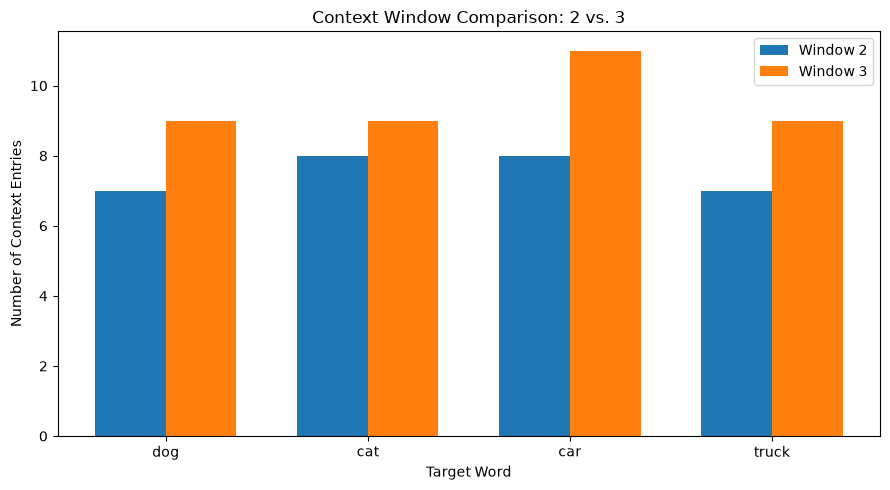

In [14]:
import matplotlib.pyplot as plt

words = comparison_df["Target Word"].to_list()
counts_2 = comparison_df["Window 2"].to_list()
counts_3 = comparison_df["Window 3"].to_list()

x = range(len(words))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    [i - width / 2 for i in x],
    counts_2,
    width,
    label="Window 2",
)

plt.bar(
    [i + width / 2 for i in x],
    counts_3,
    width,
    label="Window 3",
)

plt.xticks(list(x), words)
plt.xlabel("Target Word")
plt.ylabel("Number of Context Entries")
plt.title("Context Window Comparison: 2 vs. 3")
plt.legend()
plt.tight_layout()
plt.show()


## Observations and Interpretation

Increasing the context window from 2 to 3 produced additional surrounding-word entries for all four target words.

| Target Word | Window 2 | Window 3 | Increase |
|---|---:|---:|---:|
| dog | 7 | 9 | 2 |
| cat | 8 | 9 | 1 |
| car | 8 | 11 | 3 |
| truck | 7 | 9 | 2 |

The larger window revealed additional vocabulary:

- **Dog:** `kennel` and another occurrence of `the`.
- **Cat:** Another occurrence of `the`.
- **Car:** Additional context included `road` and repeated occurrences of `the`.
- **Truck:** `engine` and `loads`.

These results demonstrate that increasing the context window captures more surrounding words. Some additional words provide meaningful context, while others are common words that offer limited information.

The corpus and tokenization method remained unchanged. Therefore, changing the context window did not affect global token frequencies or bigram counts.

### Limitations

The corpus contains only 22 short, artificially constructed documents. The findings demonstrate how context windows work but should not be generalized to larger or more complex text collections.

The analysis also retains common words such as `the`, which can make some co-occurrence results less informative.

## Conclusion

Increasing the context window from 2 to 3 captured more nearby words for every target term. However, more context does not necessarily mean more useful context.

This experiment helped me understand how changing the context window affects the results and why a larger window isn't always better.



In [15]:
# Verify that the comparison uses the complete context lists.
assert len(corpus) == 22
assert len(context_2["dog"]) == 7
assert len(context_3["dog"]) == 9
assert len(context_2["cat"]) == 8
assert len(context_3["cat"]) == 9
assert len(context_2["car"]) == 8
assert len(context_3["car"]) == 11
assert len(context_2["truck"]) == 7
assert len(context_3["truck"]) == 9

print("Phase 4 comparison verified successfully.")

Phase 4 comparison verified successfully.
